# Fatores associados à vitória do mandante

Este notebook investiga duas perguntas:

1. As temporadas de 2008 e 2017 são realmente atípicas na distribuição dos resultados?
2. Quais características disponíveis antes da partida estão associadas à vitória do mandante?

A análise separa **explicação estatística** de **predição**. Associação não significa causalidade, e variáveis produzidas durante o jogo não serão usadas para prever seu resultado.

## 1. Preparação

In [35]:
# Biblioteca padrão para criar pastas e montar caminhos de arquivos.
import os

# Matplotlib controla a criação, os títulos, os eixos e a exportação dos gráficos.
import matplotlib.pyplot as plt
# NumPy fornece operações numéricas, vetores e funções matemáticas.
import numpy as np
# Pandas lê o CSV e permite trabalhar com tabelas chamadas DataFrames.
import pandas as pd
# Seaborn cria visualizações estatísticas usando o Matplotlib como base.
import seaborn as sns
# Statsmodels ajusta a regressão explicativa e fornece p-valores e intervalos.
import statsmodels.api as sm
# display mostra tabelas formatadas dentro do notebook.
from IPython.display import display
# binomtest testa uma proporção; chi2_contingency compara distribuições categóricas.
from scipy.stats import binomtest, chi2_contingency
# calibration_curve compara probabilidades previstas com frequências observadas.
from sklearn.calibration import calibration_curve
# DummyClassifier cria um modelo simples de referência, chamado baseline.
from sklearn.dummy import DummyClassifier
# LogisticRegression cria o modelo preditivo de vitória do mandante.
from sklearn.linear_model import LogisticRegression
# Métricas para medir acertos, discriminação e qualidade das probabilidades.
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
# make_pipeline encadeia padronização e regressão em um único objeto.
from sklearn.pipeline import make_pipeline
# StandardScaler coloca as variáveis na mesma escala: média 0 e desvio-padrão 1.
from sklearn.preprocessing import StandardScaler
# multipletests corrige p-valores quando várias hipóteses são testadas.
from statsmodels.stats.multitest import multipletests
# proportion_confint calcula intervalos de confiança para proporções.
from statsmodels.stats.proportion import proportion_confint

# Define fundo branco com linhas de grade para facilitar comparações visuais.
sns.set_theme(style="whitegrid", palette="pastel", font_scale=1.2)
# Permite visualizar até 50 colunas quando uma tabela for exibida.
pd.set_option("display.max_columns", 50)

In [36]:
CAMINHO_DADOS = r"C:\Users\Airton Sammi\airton_sammi_labs\nexo-dados-lab\projects\brasileirao\data\raw\brasileirao_serie_a.csv"
PASTA_GRAFICOS = r"C:\Users\Airton Sammi\airton_sammi_labs\nexo-dados-lab\projects\brasileirao\reports\figures"

os.makedirs(PASTA_GRAFICOS, exist_ok=True)
df = pd.read_csv(CAMINHO_DADOS, parse_dates=["data"], low_memory=False)

partidas = df.dropna(subset=["gols_mandante", "gols_visitante"]).copy()
partidas["mandante_venceu"] = (partidas["gols_mandante"] > partidas["gols_visitante"]).astype(int)
partidas["resultado"] = "Empate"
partidas.loc[partidas["gols_mandante"] > partidas["gols_visitante"], "resultado"] = "Vitória do mandante"
partidas.loc[partidas["gols_mandante"] < partidas["gols_visitante"], "resultado"] = "Vitória do visitante"

print(f"Partidas com placar válido: {len(partidas):,}")
print(f"Período: {partidas['data'].min().date()} a {partidas['data'].max().date()}")

Partidas com placar válido: 8,452
Período: 2003-03-29 a 2024-10-26


## 2. A taxa de vitória do mandante varia entre temporadas?

### Comentário do professor

A unidade de análise é a partida. Para cada temporada calculamos a proporção de jogos em que o mandante venceu. Uma taxa de 0,50, ou 50%, significa que metade dos jogos terminou com vitória do time da casa.

**Métricas utilizadas:**

- **Taxa de vitória:** `vitórias do mandante / total de jogos`. Mede a frequência observada, mas não sua incerteza.
- **Intervalo de confiança de 95%:** faixa de valores compatíveis com os dados. Usamos Wilson porque costuma funcionar melhor para proporções do que a aproximação normal simples. Intervalos sobrepostos sugerem cautela ao declarar que duas temporadas são diferentes.
- **Z-score:** quantidade de desvios-padrão entre a taxa da temporada e a média das taxas. Valores positivos indicam mais vitórias mandantes; negativos indicam menos. Valores absolutos próximos ou acima de 2 merecem investigação, mas não constituem prova isolada.

O tamanho da amostra é fundamental: uma mesma taxa é mais precisa quando baseada em 380 jogos do que em 20.

In [37]:
resumo_temporadas = (
    partidas.groupby("ano_campeonato")
    .agg(
        jogos=("mandante_venceu", "size"),
        vitorias_mandante=("mandante_venceu", "sum"),
    )
    .reset_index()
)

resumo_temporadas["taxa_vitoria"] = resumo_temporadas["vitorias_mandante"] / resumo_temporadas["jogos"]
taxa_historica = partidas["mandante_venceu"].mean()

intervalos = resumo_temporadas.apply(
    lambda linha: proportion_confint(
        count=linha["vitorias_mandante"],
        nobs=linha["jogos"],
        alpha=0.05,
        method="wilson",
    ),
    axis=1,
)
resumo_temporadas[["ic_inferior", "ic_superior"]] = pd.DataFrame(intervalos.tolist(), index=resumo_temporadas.index)

media_taxas = resumo_temporadas["taxa_vitoria"].mean()
desvio_taxas = resumo_temporadas["taxa_vitoria"].std()
resumo_temporadas["z_score"] = (resumo_temporadas["taxa_vitoria"] - media_taxas) / desvio_taxas

colunas_percentuais = ["taxa_vitoria", "ic_inferior", "ic_superior"]
resumo_temporadas[colunas_percentuais] = resumo_temporadas[colunas_percentuais] * 100
resumo_temporadas.round(2)

,ano_campeonato,jogos,vitorias_mandante,taxa_vitoria,ic_inferior,ic_superior,z_score
0,2003,456,244,53.51,48.92,58.04,1.31
1,2004,456,234,51.32,46.74,55.87,0.60
2,2005,418,206,49.28,44.52,54.06,-0.05
3,2006,380,190,50.00,45.00,55.00,0.18
4,2007,380,192,50.53,45.52,55.52,0.35
5,2008,380,208,54.74,49.71,59.67,1.70
6,2009,380,195,51.32,46.30,56.30,0.60
7,2010,380,179,47.11,42.14,52.13,-0.74
8,2011,380,184,48.42,43.44,53.44,-0.32
9,2012,380,183,48.16,43.18,53.17,-0.41


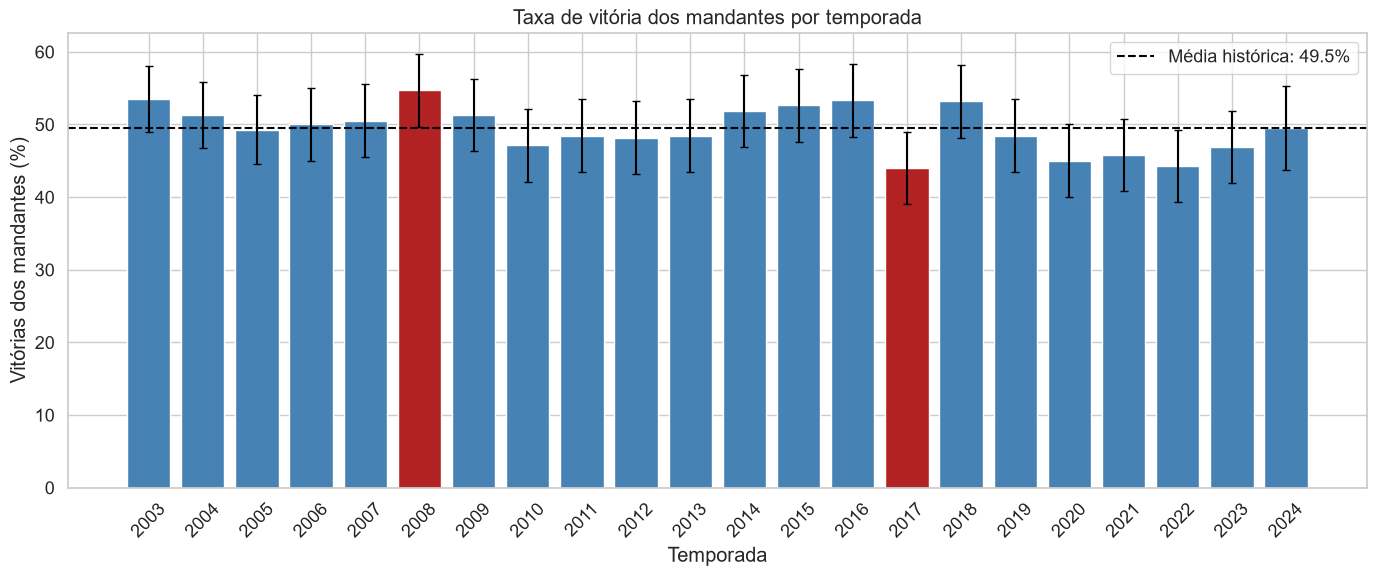

In [38]:
cores = np.where(resumo_temporadas["ano_campeonato"].isin([2008, 2017]), "firebrick", "steelblue")
erros = np.vstack([
    resumo_temporadas["taxa_vitoria"] - resumo_temporadas["ic_inferior"],
    resumo_temporadas["ic_superior"] - resumo_temporadas["taxa_vitoria"],
])

plt.figure(figsize=(14, 6))
plt.bar(resumo_temporadas["ano_campeonato"].astype(str), resumo_temporadas["taxa_vitoria"], color=cores)
plt.errorbar(
    x=np.arange(len(resumo_temporadas)),
    y=resumo_temporadas["taxa_vitoria"],
    yerr=erros,
    fmt="none",
    ecolor="black",
    capsize=3,
)
plt.axhline(taxa_historica * 100, color="black", linestyle="--", label=f"Média histórica: {taxa_historica:.1%}")
plt.title("Taxa de vitória dos mandantes por temporada")
plt.xlabel("Temporada")
plt.ylabel("Vitórias dos mandantes (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PASTA_GRAFICOS, "taxa_vitoria_mandante_com_intervalos.png"), dpi=150)
plt.show()

## 3. 2008 e 2017 são desvios estatísticos?

### Comentário do professor

O gráfico sugere hipóteses; o teste estatístico mede se o afastamento é maior do que esperaríamos por variação aleatória.

**Teste binomial:** compara o número de vitórias mandantes de uma temporada com a taxa observada nas demais temporadas. A hipótese nula afirma que a temporada segue a mesma probabilidade de referência.

**P-valor:** probabilidade de observar um resultado tão extremo quanto o encontrado, supondo que a hipótese nula seja verdadeira. Não é a probabilidade de a hipótese estar correta.

**Correção de Holm:** como testamos 22 temporadas, aumentaria a chance de encontrar ao menos um falso positivo. Holm ajusta os p-valores para controlar esse risco. Usamos `p ajustado < 0,05` como evidência de desvio.

Como 2008 e 2017 foram selecionados depois de olhar o gráfico, a análise é exploratória. Uma confirmação mais forte exigiria definir os anos antes de observar os resultados ou testar a hipótese em novos dados.

In [39]:
resultados_testes = []

for ano in resumo_temporadas["ano_campeonato"]:
    temporada = partidas[partidas["ano_campeonato"] == ano]
    demais = partidas[partidas["ano_campeonato"] != ano]

    teste = binomtest(
        k=temporada["mandante_venceu"].sum(),
        n=len(temporada),
        p=demais["mandante_venceu"].mean(),
        alternative="two-sided",
    )

    resultados_testes.append({
        "ano_campeonato": ano,
        "p_valor": teste.pvalue,
    })

testes_temporadas = pd.DataFrame(resultados_testes)
testes_temporadas["p_ajustado_holm"] = multipletests(
    testes_temporadas["p_valor"],
    method="holm",
)[1]

diagnostico_temporadas = resumo_temporadas.merge(testes_temporadas, on="ano_campeonato")
diagnostico_temporadas["desvio_estatistico"] = diagnostico_temporadas["p_ajustado_holm"] < 0.05
diagnostico_temporadas["z_score_absoluto"] = diagnostico_temporadas["z_score"].abs()

diagnostico_temporadas.sort_values("z_score_absoluto", ascending=False)[
    ["ano_campeonato", "jogos", "taxa_vitoria", "z_score", "p_valor", "p_ajustado_holm", "desvio_estatistico"]
].round(4)

,ano_campeonato,jogos,taxa_vitoria,z_score,p_valor,p_ajustado_holm,desvio_estatistico
14,2017,380,43.9474,-1.7525,0.0240,0.5290,False
5,2008,380,54.7368,1.6979,0.0353,0.7411,False
19,2022,380,44.2105,-1.6683,0.0353,0.7411,False
17,2020,380,45.0000,-1.4158,0.0725,1.0000,False
0,2003,456,53.5088,1.3052,0.0750,1.0000,False
13,2016,379,53.2982,1.2379,0.1234,1.0000,False
15,2018,380,53.1579,1.1930,0.1370,1.0000,False
18,2021,380,45.7895,-1.1634,0.1369,1.0000,False
12,2015,380,52.6316,1.0247,0.2001,1.0000,False
20,2023,380,46.8421,-0.8267,0.3049,1.0000,False


In [40]:
diagnostico_temporadas[
    diagnostico_temporadas["ano_campeonato"].isin([2008, 2017])
][
    ["ano_campeonato", "jogos", "taxa_vitoria", "ic_inferior", "ic_superior", "z_score", "p_ajustado_holm", "desvio_estatistico"]
].round(4)

,ano_campeonato,jogos,taxa_vitoria,ic_inferior,ic_superior,z_score,p_ajustado_holm,desvio_estatistico
5,2008,380,54.7368,49.7097,59.6691,1.6979,0.7411,False
14,2017,380,43.9474,39.0424,48.9735,-1.7525,0.5290,False


### A distribuição completa também mudou?

### Comentário do professor

O teste binomial reduz o resultado a vitória ou não vitória do mandante. O **qui-quadrado de independência** preserva as três categorias: vitória do mandante, empate e vitória do visitante.

- **Hipótese nula:** a distribuição dos três resultados é a mesma em todas as temporadas.
- **Qui-quadrado:** resume a distância entre frequências observadas e frequências esperadas. Valores maiores indicam maior incompatibilidade, mas sua interpretação depende dos graus de liberdade.
- **P-valor global:** informa se existe evidência de alguma diferença entre as temporadas; não diz onde ela está.
- **Resíduo padronizado:** mostra quais células mais contribuíram. Valor positivo significa mais casos que o esperado; negativo, menos. Como regra exploratória, `|resíduo| ≥ 2` merece atenção.

Um resíduo isolado não deve ser interpretado como causa. Ele apenas localiza um comportamento incomum.

In [41]:
tabela_resultados = pd.crosstab(partidas["ano_campeonato"], partidas["resultado"])
qui2, p_qui2, graus_liberdade, frequencias_esperadas = chi2_contingency(tabela_resultados)

residuos = (tabela_resultados - frequencias_esperadas) / np.sqrt(frequencias_esperadas)
residuos = pd.DataFrame(residuos, index=tabela_resultados.index, columns=tabela_resultados.columns)

print(f"Qui-quadrado: {qui2:.2f}")
print(f"Graus de liberdade: {graus_liberdade}")
print(f"p-valor: {p_qui2:.6f}")
display(residuos.loc[[2008, 2017]].round(2))

Qui-quadrado: 55.30
Graus de liberdade: 42
p-valor: 0.081906


resultado,Empate,Vitória do mandante,Vitória do visitante
ano_campeonato,,,
2008,-0.50,1.46,-1.56
2017,0.19,-1.53,2.00


In [42]:
residuos_longos = (
    residuos.stack()
    .rename("residuo_padronizado")
    .reset_index()
)
residuos_longos["residuo_absoluto"] = residuos_longos["residuo_padronizado"].abs()

residuos_longos.sort_values("residuo_absoluto", ascending=False).head(12).round(2)

,ano_campeonato,resultado,residuo_padronizado,residuo_absoluto
47,2018,Vitória do visitante,-2.40,2.40
44,2017,Vitória do visitante,2.00,2.00
2,2003,Vitória do visitante,-1.83,1.83
21,2010,Empate,1.68,1.68
17,2008,Vitória do visitante,-1.56,1.56
43,2017,Vitória do mandante,-1.53,1.53
8,2005,Vitória do visitante,1.50,1.50
58,2022,Vitória do mandante,-1.46,1.46
16,2008,Vitória do mandante,1.46,1.46
59,2022,Vitória do visitante,1.37,1.37


### Leitura dos resultados desta versão da base

Na base com dados até 26/10/2024:

- 2008 teve 54,74% de vitórias mandantes e z-score de 1,70;
- 2017 teve 43,95% de vitórias mandantes e z-score de -1,75;
- os p-valores simples são pequenos, mas deixam de ser significativos após a correção de Holm (`p` ajustado de 0,741 em 2008 e 0,529 em 2017);
- o teste global da distribuição dos três resultados teve `p = 0,0819`, acima do limite convencional de 0,05;
- em 2017, vitórias visitantes apresentaram resíduo padronizado próximo de 2, um sinal exploratório que merece investigação;
- 2022 também apresentou uma taxa baixa de vitórias mandantes, semelhante à de 2017.

Portanto, 2008 e 2017 continuam interessantes como casos exploratórios, mas não foram confirmados como anomalias estatísticas depois do controle por múltiplas comparações.

## 4. Quais fatores podem ser conhecidos antes do jogo?

### Comentário do professor

Um modelo pré-jogo só pode receber informações que estariam disponíveis no momento da previsão. Usamos posição na tabela, valor e idade média dos titulares e rodada. Público realizado, gols, chutes, faltas e escanteios ocorrem durante o jogo ou são confirmados depois.

**Cobertura percentual:** parcela de partidas em que uma variável está preenchida. Cobertura baixa reduz a amostra e pode criar viés se os dados ausentes não forem aleatórios. Se anos antigos têm mais ausências, por exemplo, o modelo representará principalmente o futebol recente.

**Vazamento de informação:** ocorre quando o modelo recebe uma informação que não existiria no momento real da previsão. Isso produz métricas artificialmente boas. Precisamos confirmar se a colocação foi registrada antes da partida; caso contrário, ela deve ser removida.

In [43]:
variaveis_candidatas = [
    "colocacao_mandante",
    "colocacao_visitante",
    "valor_equipe_titular_mandante",
    "valor_equipe_titular_visitante",
    "idade_media_titular_mandante",
    "idade_media_titular_visitante",
    "rodada",
]

cobertura = pd.DataFrame({
    "preenchidos": partidas[variaveis_candidatas].notna().sum(),
    "cobertura_pct": (partidas[variaveis_candidatas].notna().mean() * 100).round(1),
})
cobertura

,preenchidos,cobertura_pct
colocacao_mandante,6742,79.8
colocacao_visitante,6742,79.8
valor_equipe_titular_mandante,6355,75.2
valor_equipe_titular_visitante,6355,75.2
idade_media_titular_mandante,6353,75.2
idade_media_titular_visitante,6353,75.2
rodada,8452,100.0


In [44]:
dados_modelo = partidas.dropna(subset=variaveis_candidatas).copy()

# Remove valores impossíveis ou muito provavelmente digitados incorretamente.
dados_modelo = dados_modelo[
    dados_modelo["colocacao_mandante"].between(1, 30)
    & dados_modelo["colocacao_visitante"].between(1, 30)
    & dados_modelo["idade_media_titular_mandante"].between(15, 50)
    & dados_modelo["idade_media_titular_visitante"].between(15, 50)
    & (dados_modelo["valor_equipe_titular_mandante"] > 0)
    & (dados_modelo["valor_equipe_titular_visitante"] > 0)
    & (dados_modelo["rodada"] > 0)
].copy()

# Valor positivo significa vantagem do mandante.
dados_modelo["vantagem_colocacao"] = dados_modelo["colocacao_visitante"] - dados_modelo["colocacao_mandante"]
dados_modelo["vantagem_valor"] = (
    np.log1p(dados_modelo["valor_equipe_titular_mandante"])
    - np.log1p(dados_modelo["valor_equipe_titular_visitante"])
)
dados_modelo["diferenca_idade"] = (
    dados_modelo["idade_media_titular_mandante"]
    - dados_modelo["idade_media_titular_visitante"]
)

print(f"Partidas disponíveis para o modelo: {len(dados_modelo):,}")
print(f"Período do modelo: {dados_modelo['ano_campeonato'].min()} a {dados_modelo['ano_campeonato'].max()}")

Partidas disponíveis para o modelo: 6,351
Período do modelo: 2007 a 2024


## 5. Análise exploratória dos fatores

### Comentário do professor

Dividimos a vantagem de colocação em cinco grupos com aproximadamente a mesma quantidade de partidas. Esses grupos são **quintis**. Em seguida calculamos a taxa de vitória em cada grupo.

O objetivo é procurar um gradiente: quanto maior a vantagem do mandante na tabela, maior deveria ser sua taxa de vitória. Um padrão crescente fortalece a hipótese de associação, mas ainda pode refletir outras diferenças entre os clubes.

In [45]:
dados_modelo["faixa_vantagem_colocacao"] = pd.qcut(
    dados_modelo["vantagem_colocacao"],
    q=5,
    duplicates="drop",
)

taxa_por_colocacao = (
    dados_modelo.groupby("faixa_vantagem_colocacao", observed=True)
    .agg(
        jogos=("mandante_venceu", "size"),
        taxa_vitoria=("mandante_venceu", "mean"),
    )
    .reset_index()
)
taxa_por_colocacao["taxa_vitoria_pct"] = (taxa_por_colocacao["taxa_vitoria"] * 100).round(1)
taxa_por_colocacao

,faixa_vantagem_colocacao,jogos,taxa_vitoria,taxa_vitoria_pct
0,"(-19.001, -8.0]",1351,0.376758,37.7
1,"(-8.0, -3.0]",1285,0.422568,42.3
2,"(-3.0, 2.0]",1270,0.455118,45.5
3,"(2.0, 7.0]",1204,0.565615,56.6
4,"(7.0, 19.0]",1241,0.662369,66.2


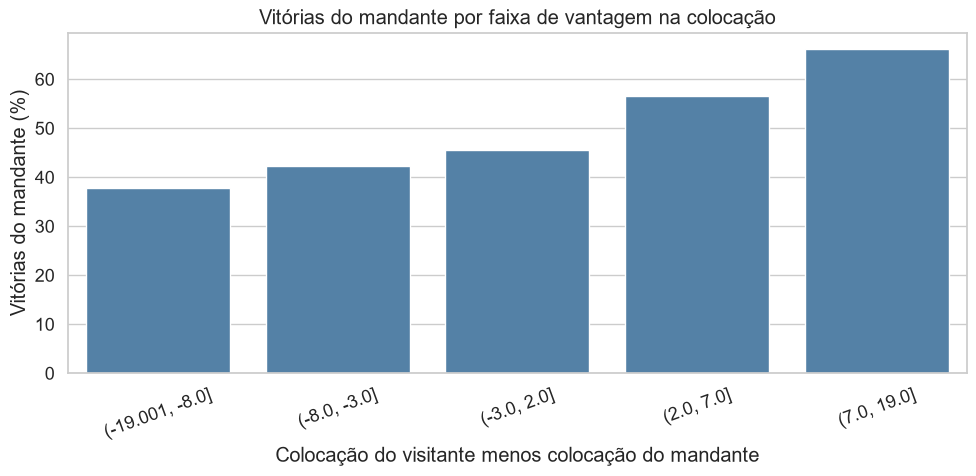

In [46]:
plt.figure(figsize=(10, 5))
sns.barplot(data=taxa_por_colocacao, x="faixa_vantagem_colocacao", y="taxa_vitoria_pct", color="steelblue")
plt.title("Vitórias do mandante por faixa de vantagem na colocação")
plt.xlabel("Colocação do visitante menos colocação do mandante")
plt.ylabel("Vitórias do mandante (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6. Regressão logística para explicação

### Comentário do professor

A regressão logística é adequada porque a resposta é binária: o mandante venceu (`1`) ou não venceu (`0`). Ela estima a associação de cada variável mantendo as demais constantes.

**Padronização:** transforma cada variável para média 0 e desvio-padrão 1. Assim, efeitos medidos em escalas diferentes podem ser comparados.

**Odds ratio:** valor acima de 1 indica aumento nas chances; abaixo de 1 indica redução. `1,34` representa aproximadamente 34% de aumento nas *odds*, não 34 pontos percentuais na probabilidade.

**Intervalo de confiança de 95%:** se incluir 1, os dados são compatíveis com ausência de associação.

**P-valor:** testa se a associação é diferente de zero. Um p-valor pequeno não mede importância prática e não prova causalidade. Observe conjuntamente odds ratio, intervalo e contexto.

In [47]:
variaveis_modelo = ["vantagem_colocacao", "vantagem_valor", "diferenca_idade", "rodada"]

X_padronizado = pd.DataFrame(
    StandardScaler().fit_transform(dados_modelo[variaveis_modelo]),
    columns=variaveis_modelo,
    index=dados_modelo.index,
)
X_inferencia = sm.add_constant(X_padronizado)
y_inferencia = dados_modelo["mandante_venceu"]

modelo_explicativo = sm.Logit(y_inferencia, X_inferencia).fit(disp=False)
intervalos_coeficientes = modelo_explicativo.conf_int()

resultado_regressao = pd.DataFrame({
    "odds_ratio": np.exp(modelo_explicativo.params),
    "ic_95_inferior": np.exp(intervalos_coeficientes[0]),
    "ic_95_superior": np.exp(intervalos_coeficientes[1]),
    "p_valor": modelo_explicativo.pvalues,
})
resultado_regressao.round(4)

,odds_ratio,ic_95_inferior,ic_95_superior,p_valor
const,0.9723,0.9241,1.0230,0.2783
vantagem_colocacao,1.3390,1.2618,1.4210,0.0000
vantagem_valor,1.3678,1.2878,1.4526,0.0000
diferenca_idade,1.0516,0.9995,1.1064,0.0523
rodada,1.0305,0.9794,1.0843,0.2463


Interpretação:

- `odds_ratio > 1`: associação com maior chance de vitória do mandante;
- `odds_ratio < 1`: associação com menor chance;
- intervalo de confiança que cruza 1: efeito compatível com ausência de associação;
- `p_valor < 0,05`: evidência estatística de associação, mas não de causalidade.

## 7. É possível prever?

### Comentário do professor

Sim, mas a avaliação deve imitar o uso real: treinamos com 2007–2021 e testamos em 2022–2024. Isso impede que informações do futuro ajudem a prever o passado. O modelo é comparado a um **baseline**, uma regra simples que usa apenas a frequência histórica.

**Acurácia:** proporção de classificações corretas usando o corte de 50%. Pode enganar quando uma classe é muito mais comum. Quanto maior, melhor.

**ROC AUC:** capacidade de ordenar partidas vencedoras acima das não vencedoras em diferentes cortes. `0,5` equivale ao acaso; `1,0` é separação perfeita. Valores próximos de `0,7` indicam discriminação moderada.

**Log loss:** avalia as probabilidades e pune fortemente previsões erradas feitas com muita confiança. Quanto menor, melhor.

**Brier score:** média do erro quadrático das probabilidades. Varia de 0 a 1; quanto menor, melhor. É fácil de interpretar como distância entre probabilidade prevista e resultado observado.

**Calibração:** verifica se partidas previstas com 60% de chance terminam em vitória aproximadamente 60% das vezes. Um modelo pode ter boa ROC AUC e probabilidades mal calibradas.

In [48]:
treino = dados_modelo[dados_modelo["ano_campeonato"] <= 2021].copy()
teste = dados_modelo[dados_modelo["ano_campeonato"] >= 2022].copy()

X_treino = treino[variaveis_modelo]
y_treino = treino["mandante_venceu"]
X_teste = teste[variaveis_modelo]
y_teste = teste["mandante_venceu"]

modelo_preditivo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)
modelo_preditivo.fit(X_treino, y_treino)

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_treino, y_treino)

print(f"Treino: {treino['ano_campeonato'].min()}–{treino['ano_campeonato'].max()} ({len(treino):,} jogos)")
print(f"Teste: {teste['ano_campeonato'].min()}–{teste['ano_campeonato'].max()} ({len(teste):,} jogos)")

Treino: 2007–2021 (5,308 jogos)
Teste: 2022–2024 (1,043 jogos)


In [49]:
def avaliar_modelo(nome, modelo, X, y):
    probabilidades = modelo.predict_proba(X)[:, 1]
    previsoes = (probabilidades >= 0.5).astype(int)

    return {
        "modelo": nome,
        "acuracia": accuracy_score(y, previsoes),
        "roc_auc": roc_auc_score(y, probabilidades),
        "log_loss": log_loss(y, probabilidades),
        "brier_score": brier_score_loss(y, probabilidades),
    }

metricas = pd.DataFrame([
    avaliar_modelo("Baseline", baseline, X_teste, y_teste),
    avaliar_modelo("Regressão logística", modelo_preditivo, X_teste, y_teste),
])
metricas.round(4)

,modelo,acuracia,roc_auc,log_loss,brier_score
0,Baseline,0.534,0.5000,0.6930,0.2499
1,Regressão logística,0.652,0.7074,0.6353,0.2220


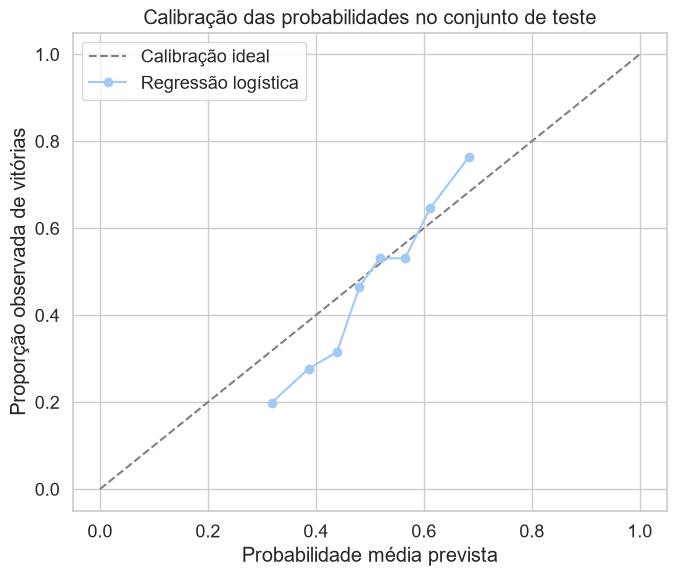

In [50]:
probabilidades_teste = modelo_preditivo.predict_proba(X_teste)[:, 1]
fracao_positivos, media_prevista = calibration_curve(y_teste, probabilidades_teste, n_bins=8, strategy="quantile")

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibração ideal")
plt.plot(media_prevista, fracao_positivos, marker="o", label="Regressão logística")
plt.title("Calibração das probabilidades no conjunto de teste")
plt.xlabel("Probabilidade média prevista")
plt.ylabel("Proporção observada de vitórias")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Estatísticas durante o jogo: explicação posterior, não previsão

### Comentário do professor

Chutes, escanteios, faltas e defesas ajudam a descrever **como** a vitória aconteceu, mas não podem ser usados para uma previsão feita antes do jogo. A tabela calcula a diferença `mandante − visitante` e depois sua média por tipo de resultado.

Uma média positiva indica que o mandante produziu mais daquela estatística; uma média negativa indica que o visitante produziu mais. Essas diferenças são associações contemporâneas ao resultado, não fatores pré-jogo nem causas comprovadas.

In [51]:
estatisticas_jogo = {
    "chutes": ("chutes_mandante", "chutes_visitante"),
    "escanteios": ("escanteios_mandante", "escanteios_visitante"),
    "faltas": ("faltas_mandante", "faltas_visitante"),
    "defesas": ("defesas_mandante", "defesas_visitante"),
}

for nome, (mandante, visitante) in estatisticas_jogo.items():
    partidas[f"diferenca_{nome}"] = partidas[mandante] - partidas[visitante]

colunas_diferencas = [f"diferenca_{nome}" for nome in estatisticas_jogo]
partidas.groupby("resultado")[colunas_diferencas].mean().round(2)

,diferenca_chutes,diferenca_escanteios,diferenca_faltas,diferenca_defesas
resultado,,,,
Empate,2.87,1.20,0.02,-0.70
Vitória do mandante,3.44,0.91,0.94,-0.80
Vitória do visitante,1.91,1.88,-0.46,-0.54


## 9. Conclusão guiada

Após executar o notebook, complete com os números encontrados:

1. **Temporadas atípicas:** 2008 e 2017 continuaram ou não significativas após a correção de Holm? Quais outros anos tiveram os maiores resíduos ou z-scores?
2. **Fatores associados:** quais razões de chances tiveram intervalo de confiança que não cruza 1?
3. **Predição:** a regressão logística superou o baseline em ROC AUC, log loss e Brier score?
4. **Limites:** a posição na tabela é realmente pré-jogo? Há dados ausentes concentrados em determinadas temporadas?
5. **Próximo passo:** testar modelos de gols com regressão de Poisson e adicionar forma recente dos clubes calculada apenas com jogos anteriores.

Uma conclusão responsável deve falar em **associação** e **capacidade preditiva fora da amostra**, não em causa comprovada.